# Trabalho Prático 1 - Modelos Lineares
**Especialização em Inteligência Artificial | Unimontes | IA-103**  
**Angel Ottoni | Outubro de 2026**

Neste trabalho, retomo os modelos lineares a partir da implementação das funções de custo e dos algoritmos de otimização. A proposta é acompanhar o que acontece entre carregar os dados, ajustar os parâmetros e interpretar uma previsão. Organizei a resolução nas quatro partes do roteiro: regressão simples, regressão múltipla, regressão logística e regularização.

Este notebook apresenta a resolução em texto próprio. O roteiro original da disciplina é mantido localmente, sem publicação. Conforme os créditos do próprio roteiro, os exercícios são uma tradução/adaptação dos trabalhos de Machine Learning de Andrew Ng, Stanford. Os dados foram fornecidos com a atividade; não são de minha autoria.

**Execução:** executar todas as células, em ordem, na pasta dos quatro arquivos `.txt`. As versões utilizadas estão em `requirements.txt`. Os resultados são calculados durante a execução, com semente 42 onde há aleatoriedade. Os gráficos também são salvos em `figuras/`.

In [1]:
from pathlib import Path
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize, check_grad
from scipy.special import expit
from sklearn.model_selection import train_test_split, StratifiedKFold

SEED = 42
FIG = Path('figuras')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 6)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG / f'{nome}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def carregar(nome, colunas):
    dados = pd.read_csv(nome, header=None, names=colunas)
    assert not dados.isna().any().any(), f'Valores ausentes em {nome}'
    assert np.isfinite(dados.to_numpy()).all()
    print(f'{nome}: {len(dados)} amostras; {dados.duplicated().sum()} duplicatas completas')
    display(dados.head())
    return dados

resultados = {'semente': SEED, 'python': platform.python_version(),
              'versoes': {p: metadata.version(p) for p in
                          ['numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn']}}
print(resultados)

{'semente': 42, 'python': '3.12.3', 'versoes': {'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}}


## 1. Regressão linear simples
Uso população e lucro nas unidades do roteiro: 10 mil habitantes e 10 mil unidades monetárias. Assim, 35 mil e 100 mil habitantes entram no modelo como 3,5 e 10. A coluna de uns representa o intercepto.

Implementei o custo $J(\theta)=\|X\theta-y\|^2/(2m)$ e a atualização batch $\theta\leftarrow\theta-\alpha X^T(X\theta-y)/m$. Todos os parâmetros são atualizados simultaneamente, usando todas as amostras.

food_truck.txt: 97 amostras; 0 duplicatas completas


,populacao,lucro
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


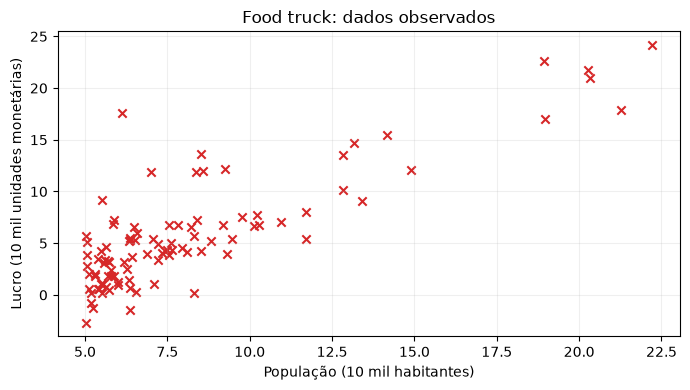

,GD (2000 iterações),Mínimos quadrados
intercepto,-3.788069,-3.895781
população,1.182213,1.193034


Custo inicial: 32.072734; final: 4.478028


In [2]:
food = carregar('food_truck.txt', ['populacao', 'lucro'])
X_food = np.column_stack([np.ones(len(food)), food.populacao])
y_food = food.lucro.to_numpy()
plt.scatter(food.populacao, y_food, marker='x', color='tab:red')
plt.xlabel('População (10 mil habitantes)')
plt.ylabel('Lucro (10 mil unidades monetárias)')
plt.title('Food truck: dados observados')
salvar('01_food_dados')

def funcao_custo(X, y, theta):
    erro = X @ np.asarray(theta).ravel() - np.asarray(y).ravel()
    return float(erro @ erro / (2 * len(y)))

def gradient_descent(X, y, theta, alpha, iterations):
    theta = np.asarray(theta, dtype=float).ravel().copy()
    y = np.asarray(y).ravel()
    historico = [funcao_custo(X, y, theta)]
    for _ in range(iterations):
        theta -= alpha * (X.T @ (X @ theta - y)) / len(y)
        historico.append(funcao_custo(X, y, theta))
    return theta, np.array(historico)

theta_zero = np.zeros(2)
custo_inicial = funcao_custo(X_food, y_food, theta_zero)
assert np.isclose(custo_inicial, 32.072733877455676)
theta_food, hist_food = gradient_descent(X_food, y_food, theta_zero, .01, 2000)
theta_ref = np.linalg.lstsq(X_food, y_food, rcond=None)[0]
display(pd.DataFrame({'GD (2000 iterações)': theta_food, 'Mínimos quadrados': theta_ref},
                     index=['intercepto', 'população']))
print(f'Custo inicial: {custo_inicial:.6f}; final: {hist_food[-1]:.6f}')
assert hist_food[-1] < custo_inicial
assert np.all(np.diff(hist_food) <= 1e-10)
theta_longo, _ = gradient_descent(X_food, y_food, theta_zero, .01, 15000)
assert np.allclose(theta_longo, theta_ref, atol=1e-7)

### Taxa de aprendizado, iterações e previsões
Comparo três taxas estáveis e uma acima do limite de estabilidade da função quadrática. Esse limite é calculado a partir do maior autovalor de $X^TX/m$: precisamos de $0 < \alpha < 2/\lambda_{max}$ para convergência nesta tarefa. Uma execução com 2.000 atualizações não é, por si só, evidência de convergência completa.

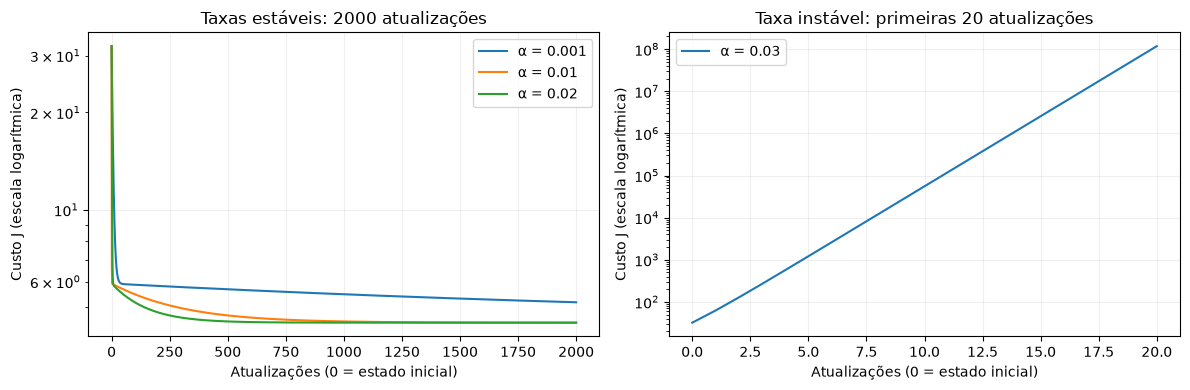

,alpha,iteracoes,theta_0,theta_1,custo_final
0,0.001,2000,-1.123690,0.914547,5.176563e+00
1,0.010,2000,-3.788069,1.182213,4.478028e+00
2,0.020,2000,-3.892881,1.192742,4.476972e+00
3,0.030,20,-169.573160,-1683.844568,1.178589e+08


Limite teórico de estabilidade de α: 0.024324


,iteracoes,theta_0,theta_1,custo,distancia_para_referencia
0,100,-0.576556,0.859582,5.479976,3.335932e+00
1,500,-2.282867,1.030999,4.713810,1.621032e+00
2,2000,-3.788069,1.182213,4.478028,1.082545e-01
3,15000,-3.895781,1.193034,4.476971,7.048778e-12


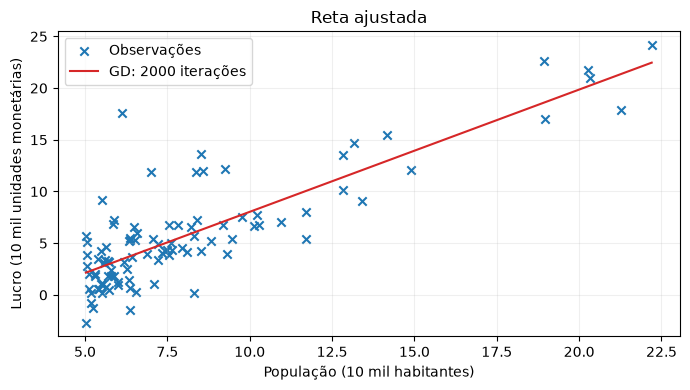

,habitantes,lucro_unidade_original,lucro_unidades_monetarias
0,35000,0.349676,3496.761389
1,100000,8.034059,80340.591749


Intervalo observado de população: 50269 a 222030 habitantes


In [3]:
limite_alpha = 2 / np.linalg.eigvalsh(X_food.T @ X_food / len(y_food)).max()
experimentos_food = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alpha in [.001, .01, .02, .03]:
    n_iter = 20 if alpha >= limite_alpha else 2000
    t, h = gradient_descent(X_food, y_food, theta_zero, alpha, n_iter)
    experimentos_food.append({'alpha': alpha, 'iteracoes': n_iter,
                             'theta_0': t[0], 'theta_1': t[1], 'custo_final': h[-1]})
    ax = axes[1] if alpha >= limite_alpha else axes[0]
    ax.semilogy(np.arange(len(h)), np.maximum(h, 1e-15), label=f'α = {alpha}')
for ax, titulo in zip(axes, ['Taxas estáveis: 2000 atualizações', 'Taxa instável: primeiras 20 atualizações']):
    ax.set(xlabel='Atualizações (0 = estado inicial)', ylabel='Custo J (escala logarítmica)', title=titulo)
    ax.legend()
salvar('02_food_taxas')
display(pd.DataFrame(experimentos_food))
print(f'Limite teórico de estabilidade de α: {limite_alpha:.6f}')

linhas = []
for n_iter in [100, 500, 2000, 15000]:
    t, h = gradient_descent(X_food, y_food, theta_zero, .01, n_iter)
    linhas.append({'iteracoes': n_iter, 'theta_0': t[0], 'theta_1': t[1],
                   'custo': h[-1], 'distancia_para_referencia': np.linalg.norm(t-theta_ref)})
display(pd.DataFrame(linhas))
ordem = np.argsort(X_food[:, 1])
plt.scatter(food.populacao, y_food, marker='x', label='Observações')
plt.plot(X_food[ordem, 1], X_food[ordem] @ theta_food, color='tab:red', label='GD: 2000 iterações')
plt.xlabel('População (10 mil habitantes)')
plt.ylabel('Lucro (10 mil unidades monetárias)')
plt.title('Reta ajustada')
plt.legend()
salvar('03_food_reta')
populacoes = np.array([35000, 100000])
lucros = np.column_stack([np.ones(2), populacoes/10000]) @ theta_food
display(pd.DataFrame({'habitantes': populacoes, 'lucro_unidade_original': lucros,
                      'lucro_unidades_monetarias': lucros*10000}))
print(f'Intervalo observado de população: {food.populacao.min()*10000:.0f} a '
      f'{food.populacao.max()*10000:.0f} habitantes')
resultados['simples'] = {'theta': theta_food.tolist(), 'theta_referencia': theta_ref.tolist(),
                        'custo_inicial': custo_inicial, 'custo_final': hist_food[-1],
                        'lucros': (lucros*10000).tolist(), 'alpha_limite': limite_alpha}

**Análise.** A taxa menor reduz o custo mais lentamente; a taxa acima do limite faz o erro crescer. A comparação com mínimos quadrados mostra por que os coeficientes ainda mudam ao aumentar as iterações. Os valores aproximados citados no roteiro correspondem a um estágio do ajuste, não a uma solução única para qualquer número de iterações. Mantenho as previsões com α = 0,01 e 2.000 atualizações para vinculá-las ao experimento apresentado.

A previsão para 35 mil habitantes extrapola o intervalo da base. Ela responde ao exercício, mas exige mais cautela do que a previsão para 100 mil. Além disso, a associação entre população e lucro não demonstra causalidade nem contempla todas as condições para abertura de uma filial.

## 2. Regressão linear múltipla
Nesta parte, uso área e quantidade de quartos para estimar preço. Padronizo cada atributo pela média e pelo desvio padrão populacional (`ddof=0`). Preservo a coluna de intercepto e reutilizo as estatísticas do treinamento na nova observação. Para colunas constantes, adoto divisor 1, evitando divisão por zero.

imoveis.txt: 47 amostras; 0 duplicatas completas


,area,quartos,preco
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


,media,desvio
intercepto,0.000000,1.000000
area,2000.680851,786.202619
quartos,3.170213,0.752843


,intercepto,area_padronizada,quartos_padronizados
0,1.0,0.131415,-0.226093
1,1.0,-0.509641,-0.226093
2,1.0,0.507909,-0.226093
3,1.0,-0.743677,-1.554392
4,1.0,1.271071,1.102205


,GD,referencia
0,340412.658940,340412.659574
1,109439.225782,109447.796470
2,-6569.784167,-6578.354854


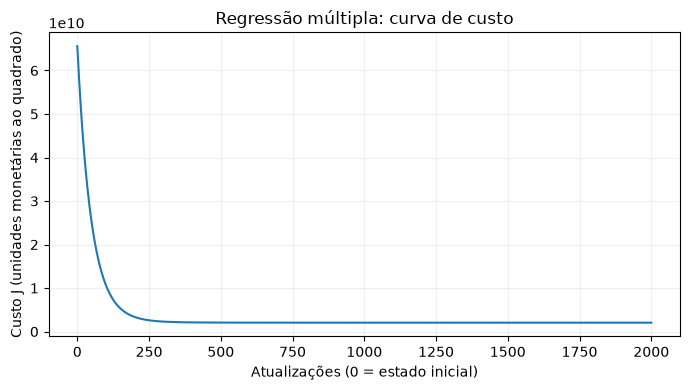

Preço estimado para 1650 pés² e 3 quartos: 293,083.35 unidades monetárias
Preço com mínimos quadrados: 293,081.46


In [4]:
imoveis = carregar('imoveis.txt', ['area', 'quartos', 'preco'])
X_imoveis_bruto = np.column_stack([np.ones(len(imoveis)), imoveis[['area', 'quartos']]])
y_imoveis = imoveis.preco.to_numpy()

def normalize(X):
    X = np.asarray(X, dtype=float)
    mu = X.mean(axis=0)
    sigma = X.std(axis=0, ddof=0)
    sigma = np.where(sigma == 0, 1., sigma)
    # Nesta função, X já inclui o intercepto na primeira coluna.
    mu[0], sigma[0] = 0., 1.
    return (X-mu)/sigma, mu, sigma

def gradient_descent_multi(X, y, theta, alpha, iterations):
    return gradient_descent(X, y, theta, alpha, iterations)

X_imoveis, mu, sigma = normalize(X_imoveis_bruto)
assert np.allclose(X_imoveis[:, 0], 1)
assert np.allclose(X_imoveis[:, 1:].mean(axis=0), 0, atol=1e-14)
assert np.allclose(X_imoveis[:, 1:].std(axis=0), 1)
display(pd.DataFrame({'media': mu, 'desvio': sigma}, index=['intercepto', 'area', 'quartos']))
display(pd.DataFrame(X_imoveis[:5], columns=['intercepto', 'area_padronizada', 'quartos_padronizados']))
theta_imoveis, hist_imoveis = gradient_descent_multi(X_imoveis, y_imoveis, np.zeros(3), .01, 2000)
referencia_imoveis = np.linalg.lstsq(X_imoveis, y_imoveis, rcond=None)[0]
display(pd.DataFrame({'GD': theta_imoveis, 'referencia': referencia_imoveis}))
plt.plot(hist_imoveis)
plt.xlabel('Atualizações (0 = estado inicial)')
plt.ylabel('Custo J (unidades monetárias ao quadrado)')
plt.title('Regressão múltipla: curva de custo')
salvar('04_imoveis_custo')
novo_imovel = (np.array([1., 1650., 3.])-mu)/sigma
preco = float(novo_imovel @ theta_imoveis)
print(f'Preço estimado para 1650 pés² e 3 quartos: {preco:,.2f} unidades monetárias')
print(f'Preço com mínimos quadrados: {novo_imovel @ referencia_imoveis:,.2f}')
assert np.isclose(preco, novo_imovel @ referencia_imoveis, rtol=.0001)
assert np.all(np.diff(hist_imoveis) <= 1e-4)
resultados['multipla'] = {'theta': theta_imoveis.tolist(), 'preco': preco,
                        'custo_final': hist_imoveis[-1], 'mu': mu.tolist(), 'sigma': sigma.tolist()}

**Análise.** A padronização reduz a diferença de escala entre área e quartos, melhorando o caminho percorrido pelo gradiente. Isso não significa que um atributo se torne mais relevante do ponto de vista do problema. O coeficiente de quartos representa sua associação com preço mantendo a área constante; portanto, seu sinal não deve ser interpretado isoladamente como efeito causal. O custo está em escala quadrática e não pode ser comparado diretamente ao custo do food truck. Aqui também avalio ajuste na própria base, sem alegar desempenho em imóveis novos.

## 3. Regressão logística
Uso as notas de duas avaliações para estimar a probabilidade de aprovação. A hipótese é $h_\theta(x)=\sigma(X\theta)$, com $\sigma(z)=1/(1+e^{-z})$. Implementei custo, gradiente, predição e acurácia. A sigmoide numericamente estável vem de `scipy.special.expit`; o custo usa `logaddexp`, evitando calcular logaritmo de zero.

estudantes.txt: 100 amostras; 0 duplicatas completas


,avaliacao_1,avaliacao_2,aprovado
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


,z,sigmoid
0,-1000,0.000000
1,-10,0.000045
2,0,0.500000
3,10,0.999955
4,1000,1.000000


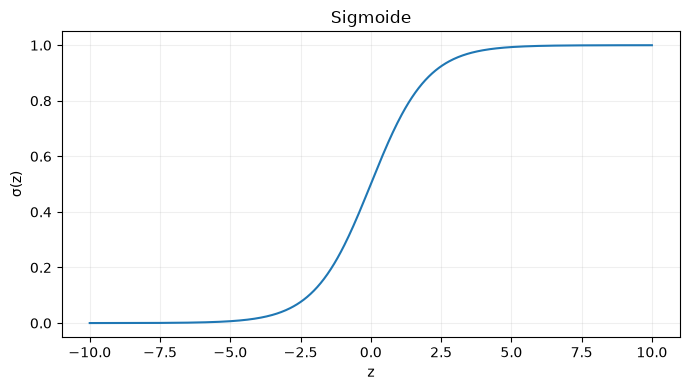

Custo inicial: 0.6931471805599453
Gradiente inicial: [ -0.1        -12.00921659 -11.26284221]
Erro absoluto da checagem numérica do gradiente: 1.21e-05


In [5]:
estudantes = carregar('estudantes.txt', ['avaliacao_1', 'avaliacao_2', 'aprovado'])
X_estudantes = np.column_stack([np.ones(len(estudantes)), estudantes.iloc[:, :2]])
y_estudantes = estudantes.aprovado.to_numpy()

def sigmoid(z):
    return expit(z)

def compute_cost(theta, X, y):
    z = X @ np.asarray(theta).ravel()
    y = np.asarray(y).ravel()
    return float(np.mean(np.logaddexp(0, z) - y*z))

def compute_gradient(theta, X, y):
    y = np.asarray(y).ravel()
    return X.T @ (sigmoid(X @ np.asarray(theta).ravel())-y) / len(y)

def predict(X, theta):
    return (sigmoid(X @ np.asarray(theta).ravel()) >= .5).astype(int)

def accuracy(X, y, theta):
    return float(np.mean(predict(X, theta) == np.asarray(y).ravel()))

display(pd.DataFrame({'z': [-1000, -10, 0, 10, 1000],
                      'sigmoid': sigmoid(np.array([-1000, -10, 0, 10, 1000]))}))
assert sigmoid(0) == .5 and sigmoid(-1000) == 0 and sigmoid(1000) == 1
grade = np.linspace(-10, 10, 500)
plt.plot(grade, sigmoid(grade))
plt.xlabel('z'); plt.ylabel('σ(z)'); plt.title('Sigmoide')
salvar('05_sigmoide')
zero_estudantes = np.zeros(3)
print('Custo inicial:', compute_cost(zero_estudantes, X_estudantes, y_estudantes))
print('Gradiente inicial:', compute_gradient(zero_estudantes, X_estudantes, y_estudantes))
assert np.isclose(compute_cost(zero_estudantes, X_estudantes, y_estudantes), np.log(2))
assert np.allclose(compute_gradient(zero_estudantes, X_estudantes, y_estudantes),
                   [-.1, -12.00921659, -11.26284221])
erro_grad = check_grad(compute_cost, compute_gradient, np.array([-.2, .01, -.01]),
                      X_estudantes, y_estudantes)
print(f'Erro absoluto da checagem numérica do gradiente: {erro_grad:.2e}')
assert erro_grad < 1e-3

### Como utilizei `scipy.optimize.minimize`
`minimize` busca parâmetros que reduzam uma função escalar de custo.  
Em `fun`, passo a função que calcula esse custo para um vetor de parâmetros.  
`x0` recebe meu vetor inicial, aqui preenchido com zeros.  
`args` transporta os dados fixos, como X e y, até as funções.  
`method='CG'` seleciona o método de gradientes conjugados não linear.  
Em `jac`, informo a função que calcula o gradiente analítico.  
`tol` controla a tolerância geral; opções como `gtol` permitem controle específico.  
`options` permite definir, entre outros ajustes, o limite `maxiter`.  
`bounds` e `constraints` dependem do método; não são usados neste ajuste com CG.  
O retorno inclui `x`, `fun`, `success` e `message`, que verifico antes de interpretar o modelo.

Referência: [documentação oficial do SciPy - minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html), consultada em 21/10/2026.

Convergência: Optimization terminated successfully.
Parâmetros: [-25.15249018   0.20616096   0.20140006]
Custo final: 0.20349771322264829


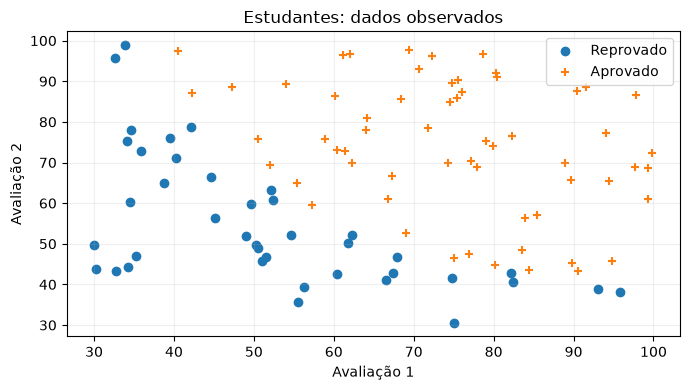

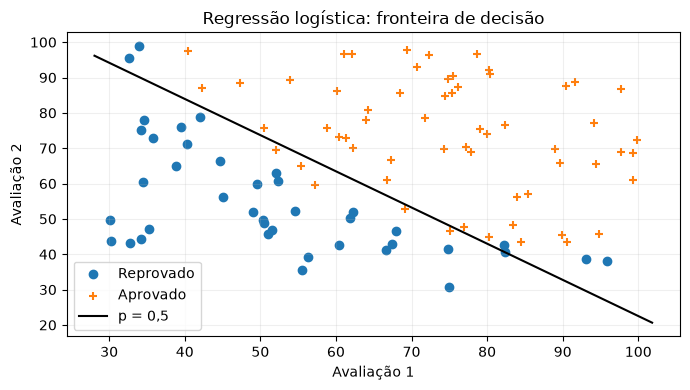

Probabilidade de aprovação (45, 85): 77.62%
Acurácia no treinamento: 89.00%


In [6]:
resultado_estudantes = minimize(compute_cost, zero_estudantes,
    args=(X_estudantes, y_estudantes), method='CG', jac=compute_gradient,
    options={'maxiter': 400, 'gtol': 1e-5})
assert resultado_estudantes.success, resultado_estudantes.message
theta_estudantes = resultado_estudantes.x
print('Convergência:', resultado_estudantes.message)
print('Parâmetros:', theta_estudantes)
print('Custo final:', resultado_estudantes.fun)

for classe, rotulo, marcador in [(0, 'Reprovado', 'o'), (1, 'Aprovado', '+')]:
    mask = y_estudantes == classe
    plt.scatter(X_estudantes[mask, 1], X_estudantes[mask, 2], label=rotulo, marker=marcador)
plt.xlabel('Avaliação 1'); plt.ylabel('Avaliação 2')
plt.title('Estudantes: dados observados'); plt.legend()
salvar('06_estudantes_dados')

for classe, rotulo, marcador in [(0, 'Reprovado', 'o'), (1, 'Aprovado', '+')]:
    mask = y_estudantes == classe
    plt.scatter(X_estudantes[mask, 1], X_estudantes[mask, 2], label=rotulo, marker=marcador)
eixo_x = np.linspace(X_estudantes[:, 1].min()-2, X_estudantes[:, 1].max()+2, 200)
eixo_y = -(theta_estudantes[0] + theta_estudantes[1]*eixo_x)/theta_estudantes[2]
plt.plot(eixo_x, eixo_y, color='black', label='p = 0,5')
plt.xlabel('Avaliação 1'); plt.ylabel('Avaliação 2')
plt.title('Regressão logística: fronteira de decisão'); plt.legend()
salvar('07_estudantes_fronteira')
probabilidade = float(sigmoid(np.array([1, 45, 85]) @ theta_estudantes))
acuracia_estudantes = accuracy(X_estudantes, y_estudantes, theta_estudantes)
print(f'Probabilidade de aprovação (45, 85): {probabilidade:.2%}')
print(f'Acurácia no treinamento: {acuracia_estudantes:.2%}')
assert .77 < probabilidade < .79
assert np.isclose(acuracia_estudantes, .89)
assert accuracy(X_estudantes, y_estudantes[:, None], theta_estudantes) == acuracia_estudantes
resultados['logistica'] = {'theta': theta_estudantes.tolist(), 'probabilidade': probabilidade,
                         'acuracia_treino': acuracia_estudantes,
                         'custo': float(resultado_estudantes.fun), 'erro_gradiente': float(erro_grad)}

**Análise.** As notas 45 e 85 resultam em uma probabilidade próxima de 0,8, como indicado no roteiro. Com limiar 0,5, a classificação é aprovação. A fronteira continua linear nos atributos originais, mesmo que a saída seja uma probabilidade. A acurácia de 89% descreve os mesmos 100 estudantes usados no ajuste; não é uma estimativa independente de generalização e não permite afirmar que as probabilidades estão calibradas.

## 4. Regularização e atributos polinomiais
Os resultados dos dois testes de microchips pedem uma fronteira mais flexível. Uso todos os monômios com grau total até 6: são 28 colunas, incluindo intercepto. O modelo continua linear nos parâmetros, mas sua fronteira pode ser curva no espaço dos dois testes.

Adoto $J_\lambda(\theta)=J(\theta)+\lambda\sum_{j=1}^{n}\theta_j^2/(2m)$. A derivada da penalização é $\lambda\theta_j/m$ e o intercepto não é penalizado. O roteiro apresenta a penalização sem o fator 1/2, mas o gradiente corresponde à convenção com esse fator. Uso custo e gradiente consistentes e verifico sua derivada numericamente.

microchips.txt: 118 amostras; 0 duplicatas completas


,teste_1,teste_2,aceito
0,0.051267,0.69956,1
1,-0.092742,0.68494,1
2,-0.213710,0.69225,1
3,-0.375000,0.50219,1
4,-0.513250,0.46564,1


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,1.0,0.051267,0.69956,0.002628,0.035864,0.489384,0.000135,0.001839,0.025089,0.342354,...,0.000900,0.012278,0.167542,1.815630e-08,2.477505e-07,0.000003,0.000046,0.000629,0.008589,0.117206
1,1.0,-0.092742,0.68494,0.008601,-0.063523,0.469143,-0.000798,0.005891,-0.043509,0.321335,...,0.002764,-0.020412,0.150752,6.362953e-07,-4.699318e-06,0.000035,-0.000256,0.001893,-0.013981,0.103256
2,1.0,-0.213710,0.69225,0.045672,-0.147941,0.479210,-0.009761,0.031616,-0.102412,0.331733,...,0.015151,-0.049077,0.158970,9.526844e-05,-3.085938e-04,0.001000,-0.003238,0.010488,-0.033973,0.110047
3,1.0,-0.375000,0.50219,0.140625,-0.188321,0.252195,-0.052734,0.070620,-0.094573,0.126650,...,0.017810,-0.023851,0.031940,2.780914e-03,-3.724126e-03,0.004987,-0.006679,0.008944,-0.011978,0.016040
4,1.0,-0.513250,0.46564,0.263426,-0.238990,0.216821,-0.135203,0.122661,-0.111283,0.100960,...,0.026596,-0.024128,0.021890,1.827990e-02,-1.658422e-02,0.015046,-0.013650,0.012384,-0.011235,0.010193


λ = 0; custo inicial = 0.693147
λ = 1; custo inicial = 0.693147
λ = 100; custo inicial = 0.693147
Custos e gradientes regularizados conferidos numericamente.


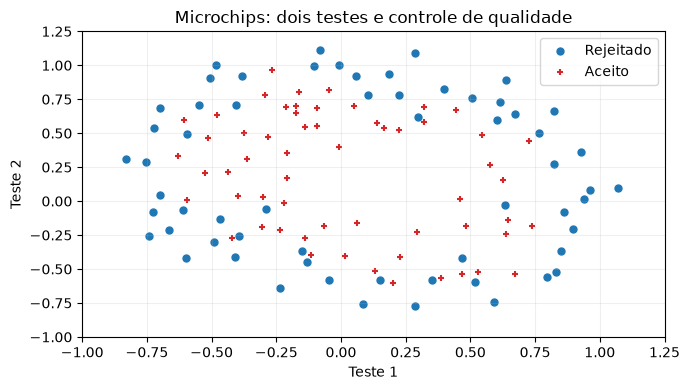

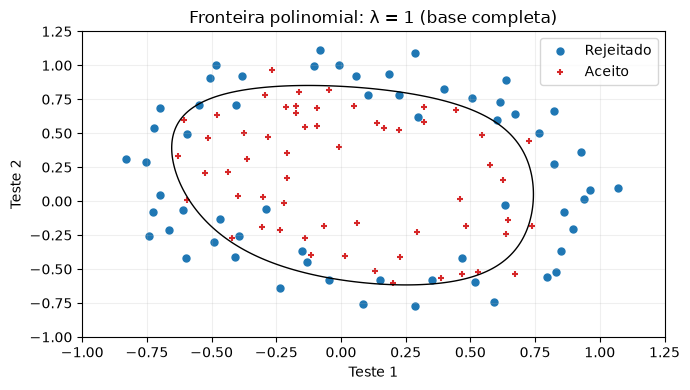

Acurácia na base completa: 83.05%


In [7]:
chips = carregar('microchips.txt', ['teste_1', 'teste_2', 'aceito'])
X_chips = chips[['teste_1', 'teste_2']].to_numpy()
y_chips = chips.aceito.to_numpy()

def map_feature(X1, X2, degree=6):
    x1, x2 = np.broadcast_arrays(np.asarray(X1), np.asarray(X2))
    return np.column_stack([(x1**(i-j) * x2**j).ravel()
                            for i in range(degree+1) for j in range(i+1)])

def compute_regularized_cost(X, y, theta, _lambda):
    theta = np.asarray(theta).ravel()
    return compute_cost(theta, X, y) + _lambda * (theta[1:] @ theta[1:])/(2*len(y))

def compute_regularized_gradient(X, y, theta, _lambda):
    theta = np.asarray(theta).ravel()
    grad = compute_gradient(theta, X, y).copy()
    grad[1:] += _lambda * theta[1:] / len(y)
    return grad

X_poly = map_feature(X_chips[:, 0], X_chips[:, 1], 6)
assert X_poly.shape == (118, 28)
assert np.allclose(map_feature([2], [3], 2), [[1, 2, 3, 4, 6, 9]])
display(pd.DataFrame(X_poly[:5]))
zero_chips = np.zeros(28)
for lam in [0., 1., 100.]:
    custo = compute_regularized_cost(X_poly, y_chips, zero_chips, lam)
    print(f'λ = {lam:g}; custo inicial = {custo:.6f}')
    assert np.isclose(custo, np.log(2))
    grad_erro = check_grad(lambda t: compute_regularized_cost(X_poly, y_chips, t, lam),
                          lambda t: compute_regularized_gradient(X_poly, y_chips, t, lam),
                          np.linspace(-.2, .2, 28))
    assert grad_erro < 1e-5
print('Custos e gradientes regularizados conferidos numericamente.')

def treinar_regularizado(X, y, lam):
    res = minimize(lambda t: compute_regularized_cost(X, y, t, lam), np.zeros(X.shape[1]),
                   jac=lambda t: compute_regularized_gradient(X, y, t, lam),
                   method='BFGS', options={'maxiter': 5000, 'gtol': 1e-7})
    # Nenhum ajuste é aceito apenas porque minimize retornou um vetor.
    assert res.success, f'λ={lam}: {res.message}'
    return res

def desenhar_chips(ax, theta=None, titulo='', indices=None):
    coords = X_chips if indices is None else X_chips[indices]
    classes = y_chips if indices is None else y_chips[indices]
    for classe, rotulo, marcador, cor in [(0, 'Rejeitado', 'o', 'tab:blue'),
                                         (1, 'Aceito', '+', 'tab:red')]:
        mask = classes == classe
        ax.scatter(coords[mask, 0], coords[mask, 1], marker=marcador,
                   color=cor, s=25, label=rotulo)
    if theta is not None:
        a, b = np.meshgrid(np.linspace(-1, 1.25, 220), np.linspace(-1, 1.25, 220))
        z = (map_feature(a, b) @ theta).reshape(a.shape)
        if z.min() <= 0 <= z.max():
            ax.contour(a, b, z, levels=[0], colors=['black'], linewidths=1)
        else:
            ax.text(.03, .03, 'Sem cruzamento p = 0,5 na grade', transform=ax.transAxes, fontsize=7)
    ax.set(xlabel='Teste 1', ylabel='Teste 2', title=titulo, xlim=(-1, 1.25), ylim=(-1, 1.25))

fig, ax = plt.subplots()
desenhar_chips(ax, titulo='Microchips: dois testes e controle de qualidade')
ax.legend()
salvar('08_chips_dados')
ajuste_completo = treinar_regularizado(X_poly, y_chips, 1.)
fig, ax = plt.subplots()
desenhar_chips(ax, ajuste_completo.x, 'Fronteira polinomial: λ = 1 (base completa)')
ax.legend()
salvar('09_chips_fronteira')
print(f'Acurácia na base completa: {accuracy(X_poly, y_chips, ajuste_completo.x):.2%}')

### Dez treinamentos adicionais: uma única divisão, dez valores de λ
Divido a base em 70% para treinamento e 30% para teste, com estratificação e semente 42. Uso exatamente a mesma divisão nos dez ajustes, evitando confundir mudança de λ com mudança das amostras. Não padronizo os testes de microchips: mantenho a escala numérica fornecida, que já está próxima da unidade. O mapeamento polinomial é determinístico e não estima estatísticas da base.

O roteiro pede identificar o melhor λ usando acurácia no teste. Vou apresentar essa comparação, mas ela transforma o teste em parte da seleção do modelo. Por isso, trato o maior valor como resultado exploratório, sem chamá-lo de desempenho final independente. Acrescento uma seleção por validação cruzada apenas no treinamento para contrastar as duas escolhas; ela também não recupera a independência do teste já consultado.

,lambda,acuracia_treino,acuracia_teste,logloss_treino,logloss_teste,norma_pesos_sem_intercepto,iteracoes,convergiu
0,0.0001,0.926829,0.833333,0.165566,1.840150,174.742092,337,True
1,0.0010,0.890244,0.833333,0.208892,0.884741,56.385384,240,True
2,0.0100,0.853659,0.833333,0.251651,0.538071,22.414794,173,True
3,0.1000,0.829268,0.805556,0.324339,0.437315,9.821683,105,True
4,0.3000,0.829268,0.805556,0.384477,0.459054,6.203777,83,True
5,1.0000,0.829268,0.777778,0.472107,0.523610,3.345363,60,True
6,3.0000,0.817073,0.666667,0.555919,0.591325,1.664677,41,True
7,10.0000,0.768293,0.611111,0.625334,0.645391,0.684345,25,True
8,100.0000,0.536585,0.500000,0.682286,0.686217,0.091799,8,True
9,1000.0000,0.512195,0.500000,0.691712,0.692671,0.009644,13,True


Amostras: treino = 82; teste = 36


,treino,teste
0,42,18
1,40,18


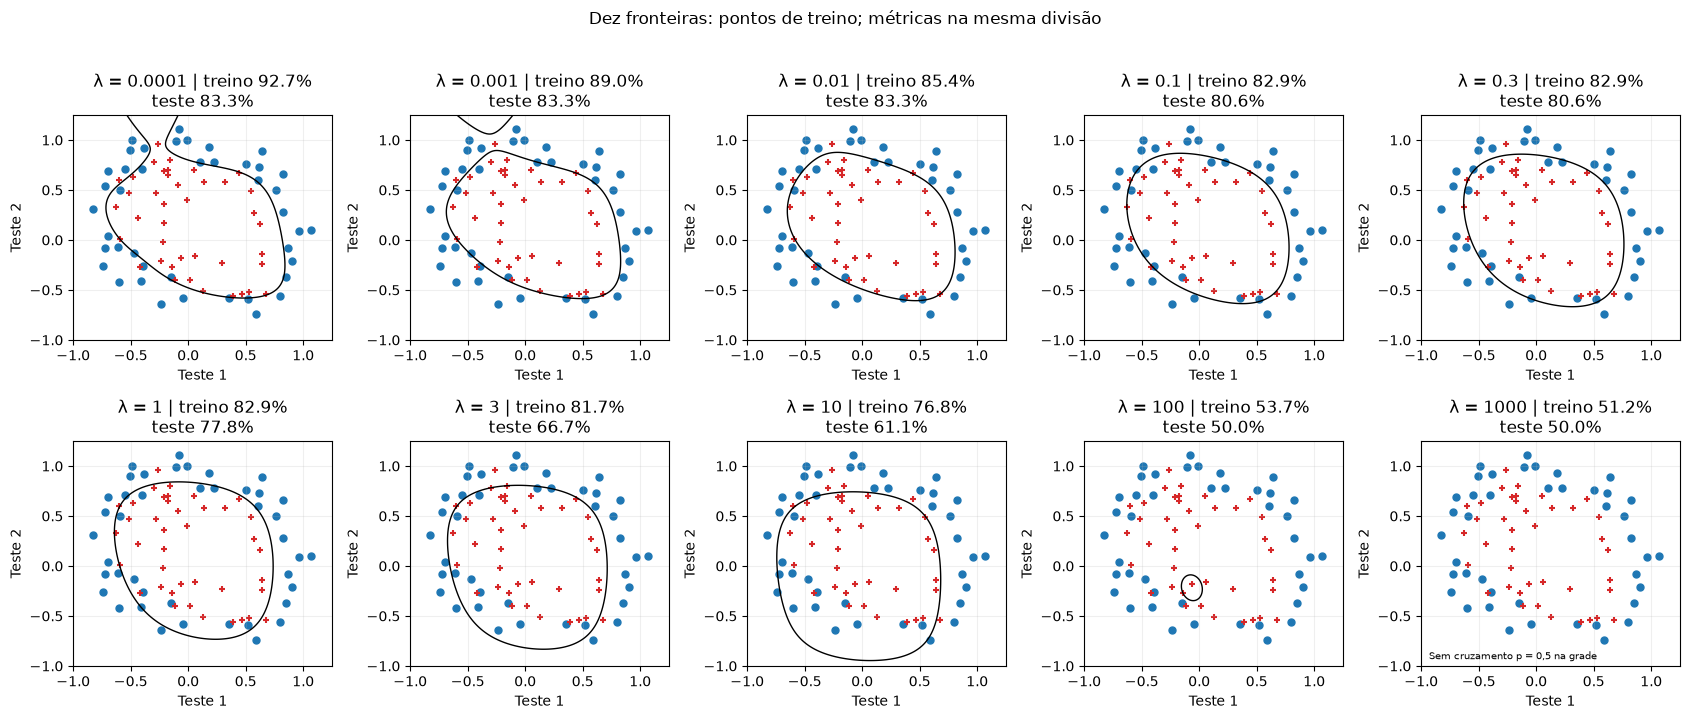

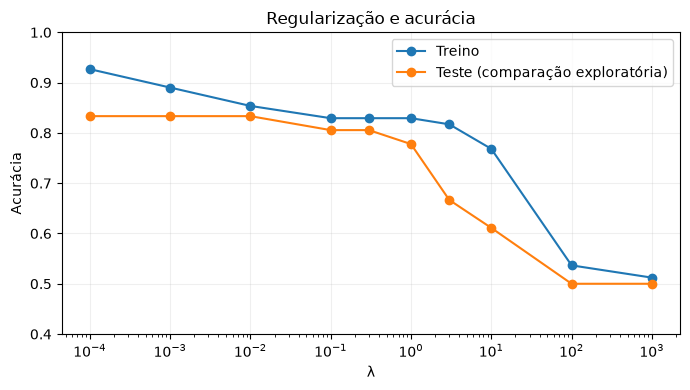

Maior acurácia observada no teste: 0.8333333333333334
Todos os valores de λ empatados no máximo: [0.0001, 0.001, 0.01]


In [8]:
idx_treino, idx_teste = train_test_split(np.arange(len(y_chips)), test_size=.3,
    stratify=y_chips, random_state=SEED)
Xt, Xv = X_poly[idx_treino], X_poly[idx_teste]
yt, yv = y_chips[idx_treino], y_chips[idx_teste]
lambdas = np.array([.0001, .001, .01, .1, .3, 1., 3., 10., 100., 1000.])
ajustes, linhas = [], []
for lam in lambdas:
    res = treinar_regularizado(Xt, yt, lam)
    ajustes.append(res)
    linhas.append({'lambda': lam, 'acuracia_treino': accuracy(Xt, yt, res.x),
                   'acuracia_teste': accuracy(Xv, yv, res.x),
                   'logloss_treino': compute_cost(res.x, Xt, yt),
                   'logloss_teste': compute_cost(res.x, Xv, yv),
                   'norma_pesos_sem_intercepto': np.linalg.norm(res.x[1:]),
                   'iteracoes': res.nit, 'convergiu': bool(res.success)})
tabela_chips = pd.DataFrame(linhas)
display(tabela_chips)
print(f'Amostras: treino = {len(yt)}; teste = {len(yv)}')
display(pd.DataFrame({'treino': pd.Series(yt).value_counts(),
                      'teste': pd.Series(yv).value_counts()}).sort_index())
assert set(idx_treino).isdisjoint(idx_teste)
assert len(idx_treino) + len(idx_teste) == len(y_chips)
assert len(ajustes) == 10
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, lam, res, linha in zip(axes.ravel(), lambdas, ajustes, linhas):
    desenhar_chips(ax, res.x, f'λ = {lam:g} | treino {linha["acuracia_treino"]:.1%}\nteste {linha["acuracia_teste"]:.1%}',
                   indices=idx_treino)
fig.suptitle('Dez fronteiras: pontos de treino; métricas na mesma divisão', y=1.02)
salvar('10_chips_dez_fronteiras')
plt.semilogx(lambdas, tabela_chips.acuracia_treino, 'o-', label='Treino')
plt.semilogx(lambdas, tabela_chips.acuracia_teste, 'o-', label='Teste (comparação exploratória)')
plt.xlabel('λ'); plt.ylabel('Acurácia'); plt.ylim(.4, 1)
plt.title('Regularização e acurácia'); plt.legend()
salvar('11_chips_acuracias')
melhor_acuracia = tabela_chips.acuracia_teste.max()
empates_teste = tabela_chips.loc[np.isclose(tabela_chips.acuracia_teste, melhor_acuracia), 'lambda'].tolist()
print('Maior acurácia observada no teste:', melhor_acuracia)
print('Todos os valores de λ empatados no máximo:', empates_teste)

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
linhas_cv = []
for lam in lambdas:
    escores = []
    for treino_cv, validacao_cv in cv.split(Xt, yt):
        res_cv = treinar_regularizado(Xt[treino_cv], yt[treino_cv], lam)
        escores.append(accuracy(Xt[validacao_cv], yt[validacao_cv], res_cv.x))
    linhas_cv.append({'lambda': lam, 'acuracia_cv_media': np.mean(escores),
                      'acuracia_cv_desvio': np.std(escores, ddof=1)})
tabela_cv = pd.DataFrame(linhas_cv)
display(tabela_cv)
# Critério definido antes da escolha: maior média; empate numérico favorece maior λ.
max_cv = tabela_cv.acuracia_cv_media.max()
lambda_cv = float(tabela_cv.loc[np.isclose(tabela_cv.acuracia_cv_media, max_cv), 'lambda'].max())
print(f'λ selecionado somente por CV no treino: {lambda_cv:g}')
print('A CV é uma análise complementar; suas médias também participam da seleção.')
resultados['regularizacao'] = {'n_treino': len(yt), 'n_teste': len(yv),
    'indices_treino': idx_treino.tolist(), 'indices_teste': idx_teste.tolist(),
    'experimentos': linhas, 'melhor_acuracia_teste': float(melhor_acuracia),
    'lambdas_empatados_teste': empates_teste, 'validacao_cruzada': linhas_cv,
    'lambda_cv': lambda_cv}
tabela_chips.to_csv('experimentos_regularizacao.csv', index=False)
tabela_cv.to_csv('validacao_cruzada.csv', index=False)
Path('resultados.json').write_text(json.dumps(resultados, ensure_ascii=False, indent=2)+'\n')
print('Resultados, índices e versões registrados em resultados.json.')

,lambda,acuracia_cv_media,acuracia_cv_desvio
0,0.0001,0.769853,0.058397
1,0.0010,0.805147,0.023106
2,0.0100,0.793382,0.051365
3,0.1000,0.794853,0.094750
4,0.3000,0.806618,0.072957
5,1.0000,0.769118,0.077092
6,3.0000,0.782353,0.074325
7,10.0000,0.698529,0.157209
8,100.0000,0.558824,0.080547
9,1000.0000,0.511765,0.016109


λ selecionado somente por CV no treino: 0.3
A CV é uma análise complementar; suas médias também participam da seleção.
Resultados, índices e versões registrados em resultados.json.


### O que os resultados permitem concluir
**Resultados desta execução.** O maior acerto no teste foi 83,33%, com empate entre λ = 0,0001, 0,001 e 0,01. A validação cruzada no treinamento selecionou λ = 0,3, com média de 80,66%; λ = 0,001 ficou em 80,51%. Essa diferença pequena não demonstra uma vantagem robusta.

**Regularização fraca.** Comparo λ = 0,0001 aos demais valores pelo formato da fronteira, pela norma dos pesos e pelas diferenças entre treino e teste. Em λ = 0,0001, obtive 92,68% no treino e 83,33% no teste, mas a perda logística aumentou de 0,166 para 1,840. A norma dos pesos chegou a 174,74. Essa combinação, junto da fronteira mais complexa, é compatível com overfitting, mesmo com empate na acurácia de teste. O comportamento de uma única divisão, porém, não basta para provar esse diagnóstico.

**Regularização excessiva.** Em λ = 1000, a penalização restringe os pesos e o ajuste perde capacidade de representar a região de aceitação. As acurácias caíram para 51,22% no treino e 50,00% no teste, resultado compatível com underfitting. Os gráficos permitem verificar como a fronteira se simplifica.

**Escolha de λ.** A tabela mostra todos os empates no maior acerto do teste; não atribuo uma superioridade inexistente a apenas um deles. Comparo esse conjunto com o λ escolhido pela validação cruzada no treino. Como o teste tem apenas 36 amostras, uma única previsão altera sua acurácia em aproximadamente 2,78 pontos percentuais. Isso limita a força de diferenças pequenas entre configurações.

## 5. Conclusões
O exercício reforçou que implementar uma função de custo não encerra a análise. Preciso conferir sua derivada, acompanhar a otimização, respeitar as unidades dos dados e distinguir ajuste de generalização. A padronização ajudou o gradiente na regressão múltipla; os termos polinomiais deram flexibilidade à logística; a regularização controlou essa flexibilidade.

Os resultados respondem às tarefas propostas, mas vêm de bases pequenas e de experimentos didáticos. Para avaliar um modelo destinado ao uso real, eu reservaria um conjunto final que não participasse da escolha dos hiperparâmetros, repetiria a avaliação com outras divisões e investigaria os erros além da acurácia.

## Referências e autoria
- Roteiro e quatro bases disponibilizados na disciplina IA-103, Unimontes. Materiais originais mantidos localmente e fora do Git.
- Créditos informados no roteiro: adaptação de atividades de Machine Learning, Andrew Ng, Stanford.
- [SciPy: minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html). Consulta em 21/10/2026.
- Resolução preparada com apoio de IA na implementação, redação e verificação. Os resultados numéricos vêm da execução do código apresentado. A revisão e a compreensão antes da submissão cabem ao autor.